<a href="https://colab.research.google.com/github/kianli53/credit-card-fraud-detection-ml-solutions/blob/main/decision_tree_random_forest_and_gradient_boosting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d kartik2112/fraud-detection
!unzip fraud-detection.zip

mkdir: cannot create directory ‘/root/.kaggle’: File exists
Dataset URL: https://www.kaggle.com/datasets/kartik2112/fraud-detection
License(s): CC0-1.0
 93% 188M/202M [00:01<00:00, 154MB/s]
100% 202M/202M [00:01<00:00, 156MB/s]
Archive:  fraud-detection.zip
  inflating: fraudTest.csv           
  inflating: fraudTrain.csv          


In [ ]:
#Imports

import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, mean_absolute_error ,mean_squared_error, confusion_matrix, median_absolute_error,classification_report, f1_score,recall_score,precision_score
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [ ]:
train_data = pd.read_csv("fraudTrain.csv") #read data
test_data = pd.read_csv("fraudTest.csv")

In [ ]:
train_data["trans_date_trans_time"] = pd.to_datetime(train_data["trans_date_trans_time"]) #convert dates and times
train_data["hour"] = train_data["trans_date_trans_time"].dt.hour
train_data["day"] = train_data["trans_date_trans_time"].dt.day
train_data["month"] = train_data["trans_date_trans_time"].dt.month
train_data = train_data.drop(columns=["trans_date_trans_time", "unix_time"])

In [ ]:
test_data["trans_date_trans_time"] = pd.to_datetime(test_data["trans_date_trans_time"]) #convert dates and times
test_data["hour"] = test_data["trans_date_trans_time"].dt.hour
test_data["day"] = test_data["trans_date_trans_time"].dt.day
test_data["month"] = test_data["trans_date_trans_time"].dt.month
test_data = test_data.drop(columns=["trans_date_trans_time", "unix_time"])

In [ ]:
#Preprocessing
train_data.drop(columns=['Unnamed: 0','cc_num','first', 'last', 'street', 'city', 'state', 'zip', 'dob', 'trans_num'],inplace=True) #drop unecessary columns
train_data

,merchant,category,amt,gender,lat,long,city_pop,job,merch_lat,merch_long,is_fraud,hour,day,month
0,"fraud_Rippin, Kub and Mann",misc_net,4.97,F,36.0788,-81.1781,3495,"Psychologist, counselling",36.011293,-82.048315,0,0,1,1
1,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,F,48.8878,-118.2105,149,Special educational needs teacher,49.159047,-118.186462,0,0,1,1
2,fraud_Lind-Buckridge,entertainment,220.11,M,42.1808,-112.2620,4154,Nature conservation officer,43.150704,-112.154481,0,0,1,1
3,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,M,46.2306,-112.1138,1939,Patent attorney,47.034331,-112.561071,0,0,1,1
4,fraud_Keeling-Crist,misc_pos,41.96,M,38.4207,-79.4629,99,Dance movement psychotherapist,38.674999,-78.632459,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,fraud_Reichel Inc,entertainment,15.56,M,37.7175,-112.4777,258,Geoscientist,36.841266,-111.690765,0,12,21,6
1296671,fraud_Abernathy and Sons,food_dining,51.70,M,39.2667,-77.5101,100,"Production assistant, television",38.906881,-78.246528,0,12,21,6
1296672,fraud_Stiedemann Ltd,food_dining,105.93,M,32.9396,-105.8189,899,Naval architect,33.619513,-105.130529,0,12,21,6
1296673,"fraud_Reinger, Weissnat and Strosin",food_dining,74.90,M,43.3526,-102.5411,1126,Volunteer coordinator,42.788940,-103.241160,0,12,21,6


In [ ]:
#Drop all rows that contain missing values
train_data.dropna(inplace=True)
test_data.dropna(inplace=True)

In [ ]:
encoder = LabelEncoder()
train_data["merchant"] = encoder.fit_transform(train_data["merchant"]) #label encode
train_data["category"] = encoder.fit_transform(train_data["category"])
train_data["gender"] = encoder.fit_transform(train_data["gender"])
train_data["job"] = encoder.fit_transform(train_data["job"])

In [ ]:
scaler = StandardScaler() #normalization
numeric_cols = ["amt", "lat", "long", "city_pop", "merch_lat", "merch_long"]
train_data[numeric_cols] = scaler.fit_transform(train_data[numeric_cols])
test_data[numeric_cols] = scaler.fit_transform(test_data[numeric_cols])
train_data

,merchant,category,amt,gender,lat,long,city_pop,job,merch_lat,merch_long,is_fraud,hour,day,month
0,514,8,-0.407826,0,-0.484420,0.657620,-0.282589,370,-0.494354,0.593864,0,0,1,1
1,241,4,0.230039,0,2.039120,-2.033870,-0.293670,428,2.078699,-2.030341,0,0,1,1
2,390,0,0.934149,1,0.717754,-1.601537,-0.280406,307,0.902849,-1.592323,0,0,1,1
3,360,2,-0.158132,1,1.515617,-1.590766,-0.287742,328,1.662886,-1.621848,0,0,1,1
4,297,9,-0.177094,1,-0.023035,0.782279,-0.293835,116,0.026941,0.841909,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,499,0,-0.341769,1,-0.161575,-1.617214,-0.293309,215,-0.331926,-1.558650,0,12,21,6
1296671,2,1,-0.116339,1,0.143638,0.924207,-0.293832,360,0.072321,0.869934,0,12,21,6
1296672,599,1,0.221930,1,-1.102883,-1.133257,-0.291186,308,-0.962433,-1.082272,0,12,21,6
1296673,509,1,0.028375,1,0.948613,-0.895029,-0.290434,485,0.832051,-0.945074,0,12,21,6


In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Separate features and target
X = train_data.drop(columns=["is_fraud"])
y = train_data["is_fraud"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Apply SMOTE
smote = SMOTE(sampling_strategy=0.5, random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Check new distribution
print(pd.Series(y_train_resampled).value_counts())

is_fraud
0    1031335
1     515667
Name: count, dtype: int64


In [ ]:
# Train Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train_resampled, y_train_resampled)

DecisionTreeClassifier(random_state=42)

In [ ]:
# Train Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_resampled, y_train_resampled)

RandomForestClassifier(random_state=42)

In [ ]:
from sklearn.metrics import classification_report, f1_score

# Make Predictions
y_pred_dt = dt.predict(X_test)

# Evaluate using F1-Score
print("Decision Tree F1-Score:", f1_score(y_test, y_pred_dt))

# Detailed Classification Report
print("\nDecision Tree Report:\n", classification_report(y_test, y_pred_dt, digits=4))

Decision Tree F1-Score: 0.3581954887218045

Decision Tree Report:
               precision    recall  f1-score   support

           0     0.9988    0.9846    0.9917    257834
           1     0.2313    0.7935    0.3582      1501

    accuracy                         0.9835    259335
   macro avg     0.6150    0.8891    0.6749    259335
weighted avg     0.9943    0.9835    0.9880    259335



In [ ]:
y_pred_rf = rf.predict(X_test)
print("Random Forest F1-Score:", f1_score(y_test, y_pred_rf))
print("\nRandom Forest Report:\n", classification_report(y_test, y_pred_rf, digits=4))

Random Forest F1-Score: 0.633788037775446

Random Forest Report:
               precision    recall  f1-score   support

           0     0.9989    0.9957    0.9973    257834
           1     0.5227    0.8048    0.6338      1501

    accuracy                         0.9946    259335
   macro avg     0.7608    0.9003    0.8155    259335
weighted avg     0.9961    0.9946    0.9952    259335



In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

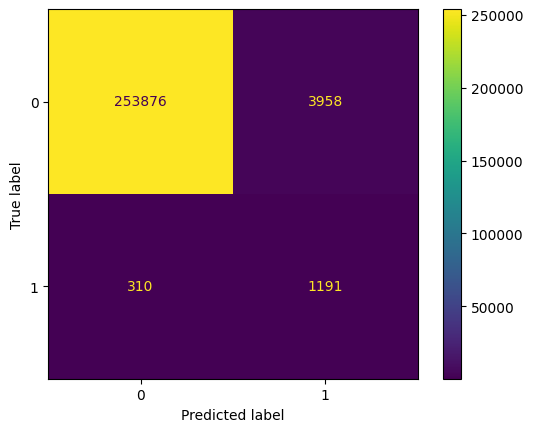

In [ ]:
#Decision tree
confusion_matrix_clf = confusion_matrix(y_test, y_pred_dt)

disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_clf)
disp.plot()

plt.show()

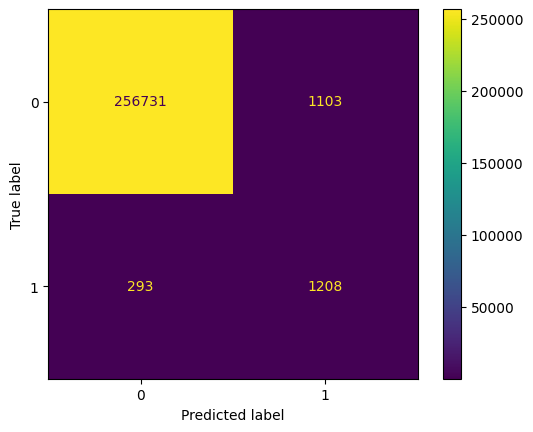

In [ ]:
#Random forest
confusion_matrix_clf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_clf)
disp.plot()

plt.show()

# **Decision tree no SMOTE**

In [ ]:
# Train Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
from sklearn.metrics import classification_report, f1_score

# Make Predictions
y_pred_dt = dt.predict(X_test)

# Evaluate using F1-Score
print("Decision Tree F1-Score:", f1_score(y_test, y_pred_dt))

# Detailed Classification Report
print("\nDecision Tree Report:\n", classification_report(y_test, y_pred_dt, digits=4))

Decision Tree F1-Score: 0.7367380560131795

Decision Tree Report:
               precision    recall  f1-score   support

           0     0.9985    0.9984    0.9985    257834
           1     0.7288    0.7448    0.7367      1501

    accuracy                         0.9969    259335
   macro avg     0.8637    0.8716    0.8676    259335
weighted avg     0.9970    0.9969    0.9969    259335



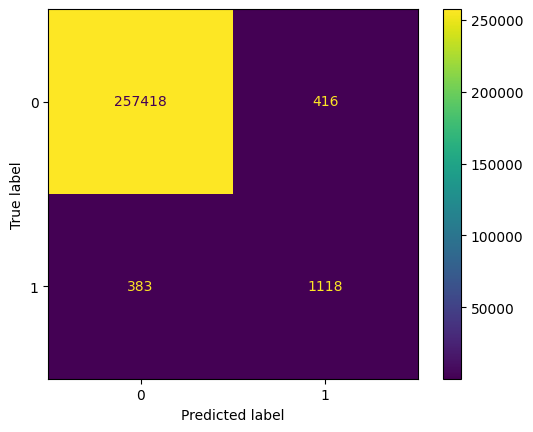

In [ ]:
#Decision tree
confusion_matrix_clf = confusion_matrix(y_test, y_pred_dt)

disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_clf)
disp.plot()

plt.show()

# **Random Forest no SMOTE**

In [ ]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
y_pred_rf = rf.predict(X_test)
print("Random Forest F1-Score:", f1_score(y_test, y_pred_rf))
print("\nRandom Forest Report:\n", classification_report(y_test, y_pred_rf, digits=4))

Random Forest F1-Score: 0.8090145148968678

Random Forest Report:
               precision    recall  f1-score   support

           0     0.9983    0.9998    0.9990    257834
           1     0.9481    0.7055    0.8090      1501

    accuracy                         0.9981    259335
   macro avg     0.9732    0.8527    0.9040    259335
weighted avg     0.9980    0.9981    0.9979    259335



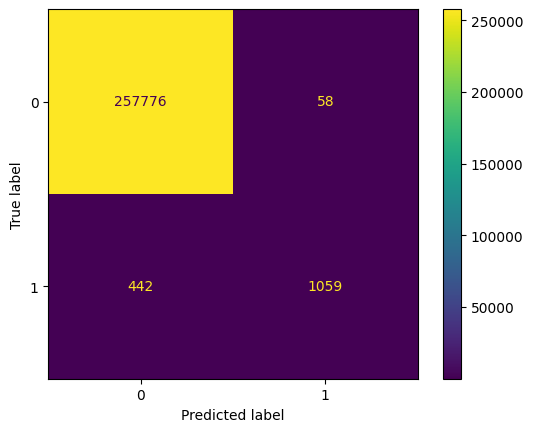

In [ ]:
#Random forest
confusion_matrix_clf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_clf)
disp.plot()

plt.show()

# **Gradient Boosting no SMOTE**

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

In [ ]:
gb = GradientBoostingClassifier( learning_rate = 0.1, max_depth = None, max_leaf_nodes=30,min_samples_leaf=22)

In [ ]:
gb.fit(X_train , y_train)

GradientBoostingClassifier(max_depth=None, max_leaf_nodes=30,
                           min_samples_leaf=22)

In [ ]:
y_pred_gb = gb.predict(X_test)

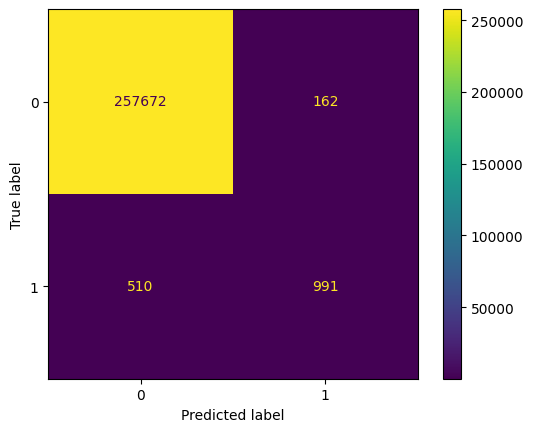

In [ ]:
confusion_matrix_clf = confusion_matrix(y_test, y_pred_gb)

disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_clf)
disp.plot()

plt.show()

In [ ]:
# Detailed Classification Report
print("\nDecision Tree Report:\n", classification_report(y_test, y_pred_gb, digits=4))


Decision Tree Report:
               precision    recall  f1-score   support

           0     0.9980    0.9994    0.9987    257834
           1     0.8595    0.6602    0.7468      1501

    accuracy                         0.9974    259335
   macro avg     0.9288    0.8298    0.8727    259335
weighted avg     0.9972    0.9974    0.9972    259335



# **Gradient Boosting SMOTE**

In [ ]:
gbs = GradientBoostingClassifier( learning_rate = 0.1, max_depth = None, max_leaf_nodes=30,min_samples_leaf=22)

In [ ]:
gbs.fit(X_train_resampled , y_train_resampled)

GradientBoostingClassifier(max_depth=None, max_leaf_nodes=30,
                           min_samples_leaf=22)

In [ ]:
y_pred_gbs = gbs.predict(X_test)

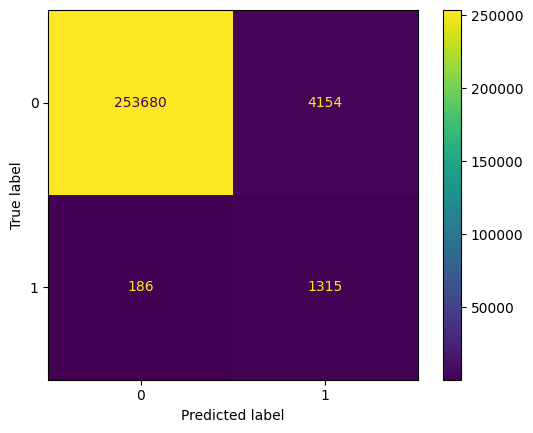

In [ ]:
confusion_matrix_clf = confusion_matrix(y_test, y_pred_gbs)

disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_clf)
disp.plot()

plt.show()

In [ ]:
# Detailed Classification Report

precision_score_ab =  precision_score(y_test, y_pred_gbs)
accuracy_score_ab = accuracy_score(y_test, y_pred_gbs)
print('The precision score is : ',round(precision_score_ab * 100,2), '%')
print('The accuracy score is : ',round(accuracy_score_ab * 100,2), '%')
print("\nDecision Tree Report:\n", classification_report(y_test, y_pred_gbs, digits=4))

The precision score is :  24.04 %
The accuracy score is :  98.33 %

Decision Tree Report:
               precision    recall  f1-score   support

           0     0.9993    0.9839    0.9915    257834
           1     0.2404    0.8761    0.3773      1501

    accuracy                         0.9833    259335
   macro avg     0.6199    0.9300    0.6844    259335
weighted avg     0.9949    0.9833    0.9880    259335



# **XGboost**

In [ ]:
from xgboost import XGBRegressor

In [ ]:
xgb = XGBRegressor(n_estimators=500, early_stopping_rounds=5)
xgb.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=5,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
y_pred = xgb.predict(X_test)

In [ ]:
y_pred = [0 if i <=0.5 else 1 for i in y_pred]

In [ ]:
precision_score_ab =  precision_score(y_test, y_pred)
accuracy_score_ab = accuracy_score(y_test, y_pred)
print('The precision score is : ',round(precision_score_ab * 100,2), '%')
print('The accuracy score is : ',round(accuracy_score_ab * 100,2), '%')
print ('\nClassification Report TEST:\n', classification_report(y_test,y_pred, digits=4))

The precision score is :  90.67 %
The accuracy score is :  99.8 %

Classification Report TEST:
               precision    recall  f1-score   support

           0     0.9985    0.9996    0.9990    257834
           1     0.9067    0.7382    0.8138      1501

    accuracy                         0.9980    259335
   macro avg     0.9526    0.8689    0.9064    259335
weighted avg     0.9979    0.9980    0.9979    259335



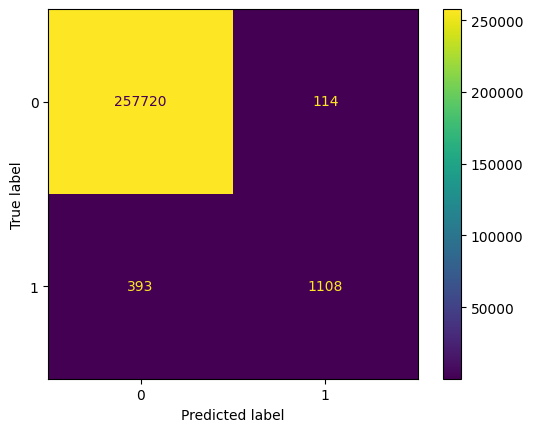

In [ ]:
confusion_matrix_clf = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_clf)
disp.plot()

plt.show()

# **XGBoost SMOTE**

In [ ]:
xgb = XGBRegressor(n_estimators=500, early_stopping_rounds=5)
xgb.fit(X_train_resampled, y_train_resampled, eval_set=[(X_test, y_test)], verbose=False)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=5,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
y_pred = xgb.predict(X_test)

In [ ]:
y_pred = [0 if i <=0.5 else 1 for i in y_pred]

In [ ]:
precision_score_ab =  precision_score(y_test, y_pred)
accuracy_score_ab = accuracy_score(y_test, y_pred)
print('The precision score is : ',round(precision_score_ab * 100,2), '%')
print('The accuracy score is : ',round(accuracy_score_ab * 100,2), '%')
print ('\nClassification Report TEST:\n', classification_report(y_test,y_pred, digits=4))

The precision score is :  49.69 %
The accuracy score is :  99.42 %

Classification Report TEST:
               precision    recall  f1-score   support

           0     0.9991    0.9950    0.9971    257834
           1     0.4969    0.8414    0.6248      1501

    accuracy                         0.9942    259335
   macro avg     0.7480    0.9182    0.8109    259335
weighted avg     0.9962    0.9942    0.9949    259335



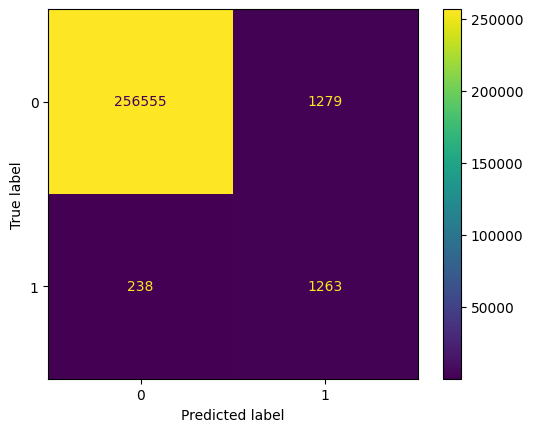

In [ ]:
confusion_matrix_clf = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_clf)
disp.plot()

plt.show()